In [3]:

from google.colab import files

uploaded = files.upload()

Saving applicants_cleaned.csv to applicants_cleaned.csv


In [4]:

import pandas as pd

df = pd.read_csv('applicants_cleaned.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (58, 7)


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Khan,applicant1@example.com,3.001000e+09,Web Development,Abc University,2026-01-01,Approved
1,Ahmed Raza,applicant2@example.com,3.001000e+09,Data Science,Xyz University,2026-01-02,Pending
2,Sara Ahmed,applicant3@example.com,3.001000e+09,Cyber Security,City University,2026-01-03,Under Review
3,Usman Malik,applicant4@example.com,3.001000e+09,App Development,National University,2026-01-04,Rejected
4,Ayesha Noor,applicant5@example.com,3.001000e+09,UI/UX Design,Tech University,2026-01-05,Approved


In [5]:

print("Dataset Information:")
df.info()

print("\nStatus Categories:")
print(df['Status'].value_counts())

print("\nDomain Categories:")
print(df['Domain Applied'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Applicant Name    58 non-null     object 
 1   Email             58 non-null     object 
 2   Phone             57 non-null     float64
 3   Domain Applied    58 non-null     object 
 4   University        58 non-null     object 
 5   Application Date  57 non-null     object 
 6   Status            58 non-null     object 
dtypes: float64(1), object(6)
memory usage: 3.3+ KB

Status Categories:
Status
Approved        15
Pending         15
Under Review    15
Rejected        13
Name: count, dtype: int64

Domain Categories:
Domain Applied
Web Development    14
Data Science       12
Cyber Security     11
App Development    11
UI/UX Design       10
Name: count, dtype: int64


In [6]:

import numpy as np

np.random.seed(42)

df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

df['has_portfolio'] = np.random.choice(
    ['Yes', 'No'], size=len(df)
)

df['prior_hackathon_participation'] = np.random.choice(
    ['Yes', 'No'], size=len(df)
)

df['statement_quality_score'] = np.random.randint(
    1, 11, size=len(df)
)

print("Simulated features added successfully!")

df.head()

Simulated features added successfully!


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Ali Khan,applicant1@example.com,3.001000e+09,Web Development,Abc University,2026-01-01,Approved,7,Yes,Yes,8
1,Ahmed Raza,applicant2@example.com,3.001000e+09,Data Science,Xyz University,2026-01-02,Pending,4,Yes,No,6
2,Sara Ahmed,applicant3@example.com,3.001000e+09,Cyber Security,City University,2026-01-03,Under Review,5,Yes,No,3
3,Usman Malik,applicant4@example.com,3.001000e+09,App Development,National University,2026-01-04,Rejected,7,Yes,Yes,1
4,Ayesha Noor,applicant5@example.com,3.001000e+09,UI/UX Design,Tech University,2026-01-05,Approved,3,Yes,No,3


In [7]:

# Remove applicants whose status is still Under Review
df_model = df[df['Status'] != 'Under Review'].copy()

# Create target variable
df_model['Selected'] = df_model['Status'].apply(
    lambda status: 1 if status == 'Approved' else 0
)

print("Target variable created successfully!")

print("\nTarget Distribution:")
print(df_model['Selected'].value_counts())

print("\nDataset Shape:", df_model.shape)

df_model[['Status', 'Selected']].head(10)

Target variable created successfully!

Target Distribution:
Selected
0    28
1    15
Name: count, dtype: int64

Dataset Shape: (43, 12)


,Status,Selected
0,Approved,1
1,Pending,0
3,Rejected,0
4,Approved,1
5,Pending,0
7,Rejected,0
8,Approved,1
9,Pending,0
11,Rejected,0
12,Approved,1


In [8]:

# Convert Yes/No columns into numeric values
df_model['has_portfolio'] = df_model['has_portfolio'].map(
    {'Yes': 1, 'No': 0}
)

df_model['prior_hackathon_participation'] = (
    df_model['prior_hackathon_participation'].map(
        {'Yes': 1, 'No': 0}
    )
)

# Encode domain categories
df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True,
    dtype=int
)

# Select model features
feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
]

domain_columns = [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

feature_columns = feature_columns + domain_columns

# Create X and y
X = df_model[feature_columns]
y = df_model['Selected']

print("Features prepared successfully!")

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features prepared successfully!

Feature Columns:
['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Cyber Security', 'Domain Applied_Data Science', 'Domain Applied_UI/UX Design', 'Domain Applied_Web Development']

Feature Shape: (43, 8)
Target Shape: (43,)


,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,Domain Applied_Cyber Security,Domain Applied_Data Science,Domain Applied_UI/UX Design,Domain Applied_Web Development
0,7,1,1,8,0,0,0,1
1,4,1,0,6,0,1,0,0
3,7,1,1,1,0,0,0,0
4,3,1,0,3,0,0,1,0
5,8,1,1,5,0,0,0,1


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train/Test Split Completed!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Train/Test Split Completed!
Training Features: (34, 8)
Testing Features: (9, 8)
Training Target: (34,)
Testing Target: (9,)


In [10]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

# Make predictions
y_pred = model.predict(X_test)

print("\nPredictions:")
print(y_pred)

Logistic Regression model trained successfully!

Predictions:
[0 0 0 1 1 0 1 0 0]


MODEL EVALUATION RESULTS
----------------------
Accuracy:  0.33
Precision: 0.00
Recall:    0.00

Confusion Matrix:
[[3 3]
 [3 0]]


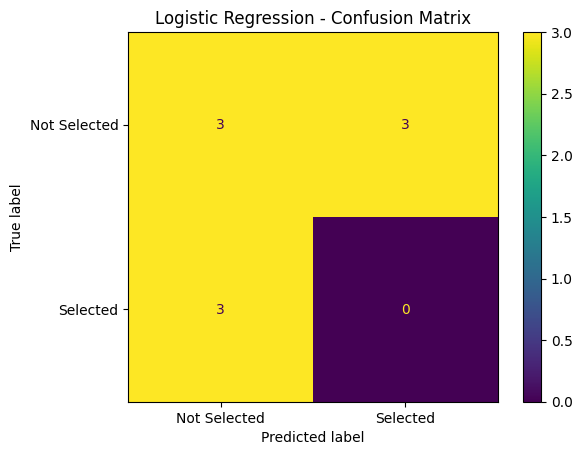

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("----------------------")
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Selected", "Selected"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

LOGISTIC REGRESSION FEATURE COEFFICIENTS
---------------------------------------
                          Feature  Coefficient
1                   has_portfolio     0.740983
2   prior_hackathon_participation     0.492534
3         statement_quality_score     0.378119
6     Domain Applied_UI/UX Design     0.216706
5     Domain Applied_Data Science     0.041487
0               num_skills_listed    -0.012954
7  Domain Applied_Web Development    -0.017466
4   Domain Applied_Cyber Security    -0.140799


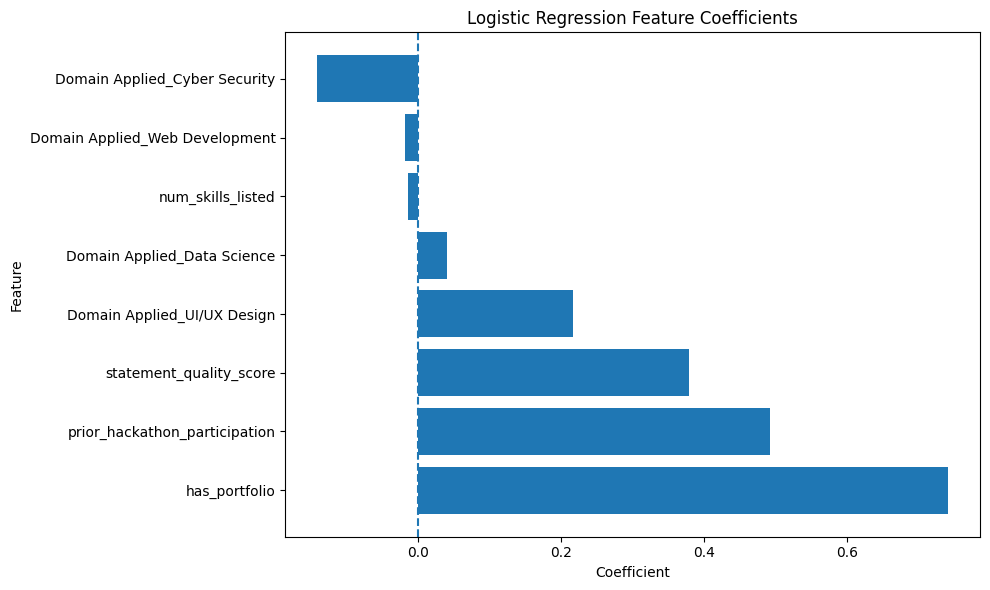

In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Get Logistic Regression coefficients
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})

# Sort coefficients
coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

print("LOGISTIC REGRESSION FEATURE COEFFICIENTS")
print("---------------------------------------")
print(coefficients)

# Plot coefficients
plt.figure(figsize=(10, 6))

plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient']
)

plt.axvline(x=0, linestyle='--')

plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Feature Interpretation

The Logistic Regression model was used to examine how the available features contributed to its selection predictions.

The model produced positive coefficients for portfolio availability, prior hackathon participation, and statement quality score. The number of skills listed had a coefficient close to zero. The domain-related coefficients showed different contributions to the model's predictions.

These coefficients describe the behavior of this particular model and should not be interpreted as actual reasons for internship selection.

Important limitation: The four applicant features were simulated rather than collected from real applicant records. The dataset is small, and the model achieved only 33.3% accuracy on a test set of nine applicants. Therefore, these results are exploratory and are not suitable for making real internship selection decisions.

Executive Summary

Internship Selection Outcome Prediction

Project Overview

This project explored whether applicant information could be used to predict internship selection outcomes. A dataset containing 58 applicants was cleaned and prepared for analysis. Applicants whose status was still Under Review were excluded, leaving 43 applicants for the modeling process.

Method

Four additional features were created using simulated data: number of skills listed, portfolio availability, prior hackathon participation, and statement quality score. These simulated features were combined with applicant domain information. A Logistic Regression model was trained using 34 applicants and evaluated using 9 test applicants.

Results

The model achieved 33.3% accuracy on the test dataset. It correctly identified three applicants as Not Selected but did not correctly identify any Selected applicants. The results indicate that the model did not perform well in this experiment.

Limitations

The dataset was small, and the four additional features were simulated rather than collected from real applicants. The test set contained only nine applicants, so the evaluation results are limited. The model's predictions and feature coefficients should not be treated as evidence of actual selection factors.

Recommendation

Future work should use a larger dataset containing verified applicant information and actual selection outcomes. The model should be tested on more data and evaluated carefully before any practical use. Internship selection should continue to involve human review, fairness checks, and transparent decision-making.